# ORI Calculation

In [1]:
import os

# Print current working directory
print(os.getcwd())

# Change to your desired directory
os.chdir('/Users/svasquez/driblab/dl-vision')
print(os.getcwd())

/Users/svasquez/driblab/dl-vision/stats/obso
/Users/svasquez/driblab/dl-vision


In [2]:
import json
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np

# Load Data

In [5]:
path = f"stats/obso/datasets/team_wide_obso_added.csv"

df = pd.read_csv(path)

df.columns

Index(['match_id', 'run_id', 'player_id', 'team_id_x', 'period',
       'xR_added_team', 'PC_added_team', 'xG_added_team', 'OBSO_added_team',
       'team_id_y', 'plyr_name', 'team_name', 'season_id', 'season_name',
       'plyr_position'],
      dtype='object')

# Formula

ORI(player) = α * mean(Top-N OBSO_added) + β * %positive_runs + γ * total_OBSO_added

Where:

Top-N OBSO_added = the top N OBSO_added runs for that player

%positive_runs = proportion of runs with OBSO_added > 0

total_OBSO_added = sum across all runs

Suggested weights (for simplicity, but can be tuned):
α = 0.5 → reward peak run impact

β = 0.3 → reward run efficiency

γ = 0.2 → include volume and consistency

In [42]:
def calc_ori(df, top_n=20, alpha=1, beta=0.5, gamma=0.1):
    ori_scores = []

    # Group by player
    for player_id, group in df.groupby("player_id"):
        plyr_name = group["plyr_name"].iloc[0]
        team_name = group["team_name"].iloc[0]

        # Sort by OBSO_added_team to get top-N
        top_n_obso = group["OBSO_added_team"].nlargest(top_n)
        mean_top_n = top_n_obso.mean()

        # % of positive runs
        pct_positive = (group["OBSO_added_team"] > 0).mean()

        # Total OBSO_added
        total_obso = group["OBSO_added_team"].sum()

        # Calculate ORI
        ori_raw = alpha * mean_top_n + beta * pct_positive + gamma * total_obso

        ori = ori_raw * np.log1p(len(group))


        ori_scores.append({
            "player_id": player_id,
            "plyr_name": plyr_name,
            "team_name": team_name,
            "ORI_raw": ori_raw,
            "ORI": ori,
            "mean_top_OBSO": mean_top_n,
            "pct_positive_runs": pct_positive,
            "total_OBSO_added": total_obso,
            "run_count": len(group)
        })

    ori_df = pd.DataFrame(ori_scores)
    return ori_df

In [43]:
ori_df = calc_ori(df)



ori_df = ori_df.sort_values(by="ORI", ascending=False)

# filter ori's with at least 30 runs

ori_df = ori_df[ori_df['run_count'] >= 30]



ori_df.head(30)

,player_id,plyr_name,team_name,ORI_raw,ORI,mean_top_OBSO,pct_positive_runs,total_OBSO_added,run_count
422,1534715,Kike Salas,Sevilla,1.081068,4.040675,0.420275,0.585366,3.6811,41
366,1329725,Aimar Oroz,Osasuna,0.955708,3.312230,0.304905,0.580645,3.6048,31
476,1776309,Lamine Yamal,FC Barcelona,0.759810,3.171741,0.359340,0.562500,1.1922,64
271,1262780,Alex Kral,Espanyol,0.697788,2.608101,0.294560,0.609756,0.9835,41
41,81045,Sergi Darder,RCD Mallorca,0.667076,2.443873,0.265440,0.552632,1.2532,38
88,199339,Javi Munoz,UD Las Palmas,0.624416,2.417239,0.368205,0.489362,0.1153,47
6,20,Antoine Griezmann,Atletico Madrid,0.536940,2.372653,0.347150,0.548780,-0.8460,82
76,189153,Sandro Ramirez,UD Las Palmas,0.642335,2.265106,0.244115,0.606061,0.9519,33
153,1159148,Ante Budimir,Osasuna,0.578563,2.251665,0.347650,0.479167,-0.0867,48
72,178273,Cedric Bakambu,Real Betis,0.602125,2.236035,0.280575,0.500000,0.7155,40


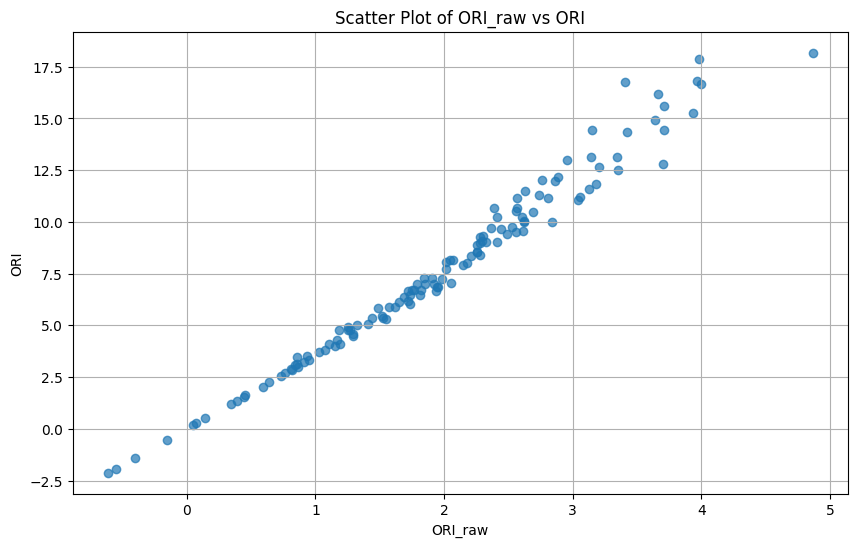

In [41]:
import matplotlib.pyplot as plt

# Create a scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(ori_df['ORI_raw'], ori_df['ORI'], alpha=0.7)

# Add labels and title
plt.xlabel('ORI_raw')
plt.ylabel('ORI')
plt.title('Scatter Plot of ORI_raw vs ORI')

# Show grid
plt.grid(True)

# Display the plot
plt.show()
